# Evaluation Metrics for Downscaling Models

## Setup

Set `REPO_ROOT` and `CONFIG_PATH` paths according to your local repository structure.  

Set `OUTPUT_DIR` to specify where output figures and tables are saved.

In [2]:
from pathlib import Path
import sys

import xarray as xr

xr.set_options(
    display_expand_data=False,
    display_expand_attrs=False,
)

In [3]:
REPO_ROOT = Path.home() / "projects" / "DL-downscaling-evaluation-EURO-CORDEX"
CONFIG_PATH = REPO_ROOT / "config" / "config.yaml"

if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

OUTPUT_DIR = REPO_ROOT / "outputs" 
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## Load data

In [4]:
from src.io import load_config, load_dataset_series


config = load_config(CONFIG_PATH)

years = range(
    config["years"]["start"],
    config["years"]["end"] + 1
)

datasets = {
    "reference": None,
    "models": {}
}


print("\n[INFO] Loading reference dataset")

datasets["reference"] = load_dataset_series(
    config["reference"],
    years,
    lazy=False
)


print("\n[INFO] Loading model output datasets")

for model_name, cfg in config["models"].items():

    print(f"\n[INFO] Loading {model_name}")

    datasets["models"][model_name] = load_dataset_series(
        cfg,
        years,
        lazy=False
    )


[INFO] Loading reference dataset
[INFO] Files:
  - /work/cmcc/mi27525/projects/FUTURA/datasets/preprocessed/EUROCORDEX/T_2M_hist_011_1hr_daymean_2005.nc
  - /work/cmcc/mi27525/projects/FUTURA/datasets/preprocessed/EUROCORDEX/T_2M_hist_011_1hr_daymean_2006.nc
  - /work/cmcc/mi27525/projects/FUTURA/datasets/preprocessed/EUROCORDEX/T_2M_hist_011_1hr_daymean_2007.nc
  - /work/cmcc/mi27525/projects/FUTURA/datasets/preprocessed/EUROCORDEX/T_2M_hist_011_1hr_daymean_2008.nc
  - /work/cmcc/mi27525/projects/FUTURA/datasets/preprocessed/EUROCORDEX/T_2M_hist_011_1hr_daymean_2009.nc
  - /work/cmcc/mi27525/projects/FUTURA/datasets/preprocessed/EUROCORDEX/T_2M_hist_011_1hr_daymean_2010.nc
  - /work/cmcc/mi27525/projects/FUTURA/datasets/preprocessed/EUROCORDEX/T_2M_hist_011_1hr_daymean_2011.nc
  - /work/cmcc/mi27525/projects/FUTURA/datasets/preprocessed/EUROCORDEX/T_2M_hist_011_1hr_daymean_2012.nc
  - /work/cmcc/mi27525/projects/FUTURA/datasets/preprocessed/EUROCORDEX/T_2M_hist_011_1hr_daymean_2013.n

/users_home/cmcc/mi27525/projects/DL-downscaling-evaluation-EURO-CORDEX/src/io.py:29: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  ds = xr.open_mfdataset(



[INFO] Loading model output datasets

[INFO] Loading ERA5-DownGAN
[INFO] Files:
  - /work/cmcc/mi27525/projects/FUTURA/outputs/ERA5-DownGAN/last/pp_20260610_153631_ensmean/ERA5-DownGAN_pp_ensmean_2005.nc
  - /work/cmcc/mi27525/projects/FUTURA/outputs/ERA5-DownGAN/last/pp_20260610_153631_ensmean/ERA5-DownGAN_pp_ensmean_2006.nc
  - /work/cmcc/mi27525/projects/FUTURA/outputs/ERA5-DownGAN/last/pp_20260610_153631_ensmean/ERA5-DownGAN_pp_ensmean_2007.nc
  - /work/cmcc/mi27525/projects/FUTURA/outputs/ERA5-DownGAN/last/pp_20260610_153631_ensmean/ERA5-DownGAN_pp_ensmean_2008.nc
  - /work/cmcc/mi27525/projects/FUTURA/outputs/ERA5-DownGAN/last/pp_20260610_153631_ensmean/ERA5-DownGAN_pp_ensmean_2009.nc
  - /work/cmcc/mi27525/projects/FUTURA/outputs/ERA5-DownGAN/last/pp_20260610_153631_ensmean/ERA5-DownGAN_pp_ensmean_2010.nc
  - /work/cmcc/mi27525/projects/FUTURA/outputs/ERA5-DownGAN/last/pp_20260610_153631_ensmean/ERA5-DownGAN_pp_ensmean_2011.nc
  - /work/cmcc/mi27525/projects/FUTURA/outputs/ERA5

/users_home/cmcc/mi27525/projects/DL-downscaling-evaluation-EURO-CORDEX/src/io.py:29: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  ds = xr.open_mfdataset(



[INFO] Loading Diffusion_DDIM
[INFO] Files:
  - /work/cmcc/mi27525/projects/FUTURA/outputs/diffusion_DDIM/last/pp_20260615_092253_ensmean/Diffusion_DDIM_ensmean_2005.nc
  - /work/cmcc/mi27525/projects/FUTURA/outputs/diffusion_DDIM/last/pp_20260615_092253_ensmean/Diffusion_DDIM_ensmean_2006.nc
  - /work/cmcc/mi27525/projects/FUTURA/outputs/diffusion_DDIM/last/pp_20260615_092253_ensmean/Diffusion_DDIM_ensmean_2007.nc
  - /work/cmcc/mi27525/projects/FUTURA/outputs/diffusion_DDIM/last/pp_20260615_092253_ensmean/Diffusion_DDIM_ensmean_2008.nc
  - /work/cmcc/mi27525/projects/FUTURA/outputs/diffusion_DDIM/last/pp_20260615_092253_ensmean/Diffusion_DDIM_ensmean_2009.nc
  - /work/cmcc/mi27525/projects/FUTURA/outputs/diffusion_DDIM/last/pp_20260615_092253_ensmean/Diffusion_DDIM_ensmean_2010.nc
  - /work/cmcc/mi27525/projects/FUTURA/outputs/diffusion_DDIM/last/pp_20260615_092253_ensmean/Diffusion_DDIM_ensmean_2011.nc
  - /work/cmcc/mi27525/projects/FUTURA/outputs/diffusion_DDIM/last/pp_20260615_0

/users_home/cmcc/mi27525/projects/DL-downscaling-evaluation-EURO-CORDEX/src/io.py:29: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  ds = xr.open_mfdataset(


### Datasets consistency

In [5]:
from src.io import check_spatiotemporal_compatibility

reference = datasets["reference"]

for model_name, da in datasets["models"].items():

    print(f"\n[INFO] Checking {model_name}")
    check_spatiotemporal_compatibility(reference, da)


[INFO] Checking ERA5-DownGAN
  time: True
  lat:  True
  lon:  True

[INFO] Checking UNet_GAN
  time: True
  lat:  True
  lon:  True

[INFO] Checking Diffusion_DDIM
  time: True
  lat:  True
  lon:  True


In [6]:
datasets['models']['UNet_GAN']

<xarray.DataArray 'T_2M' (time: 3650, rlat: 405, rlon: 418)> Size: 2GB
287.1 287.0 287.0 287.0 287.0 287.0 ... 246.5 247.0 247.6 248.3 247.5 247.5
Coordinates:
  * time     (time) object 29kB 2005-01-01 11:30:00 ... 2014-12-31 11:30:00
  * rlat     (rlat) float64 3kB -23.05 -22.93 -22.83 -22.72 ... 21.17 21.28 21.4
  * rlon     (rlon) float64 3kB -28.05 -27.93 -27.83 -27.72 ... 17.6 17.72 17.83
    lon      (rlat, rlon) float32 677kB -9.904 -9.803 -9.702 ... 63.47 63.68
    lat      (rlat, rlon) float32 677kB 22.41 22.45 22.49 ... 66.64 66.58 66.52
Attributes: (6)

## Compute metrics

In [7]:
from src.metrics import bias, mae, rmse, correlation, compute_grid_metrics

selected_metrics = [
    bias,
    mae,
    rmse,
    correlation,
]

analysis_period = {
    "start_date": "2005-01-01",
    "end_date": "2014-12-31",
}

reference = datasets["reference"]

metrics = {}

for model_name, pred in datasets["models"].items():

    print(f"\n[INFO] Computing metrics for {model_name}")

    metrics[model_name] = compute_grid_metrics(
        pred,
        reference,
        metrics=selected_metrics,
        verbose=True,
        **analysis_period,
    )


[INFO] Computing metrics for ERA5-DownGAN



Summary:

bias          mean= -0.1060   min= -1.7678   max= +1.2483
mae           mean= +1.8719   min= +0.6747   max= +4.3531
rmse          mean= +2.4114   min= +0.8647   max= +5.3063
correlation   mean= +0.9086   min= +0.5233   max= +0.9762


[INFO] Computing metrics for UNet_GAN

Summary:

bias          mean= -0.1658   min= -3.5292   max= +3.7730
mae           mean= +1.2494   min= +0.2596   max= +4.0193
rmse          mean= +1.6076   min= +0.3370   max= +4.6782
correlation   mean= +0.9753   min= +0.8696   max= +0.9963


[INFO] Computing metrics for Diffusion_DDIM

Summary:

bias          mean= -0.0305   min= -5.4522   max= +8.0992
mae           mean= +1.2719   min= +0.3990   max= +8.0992
rmse          mean= +1.6595   min= +0.4996   max= +8.4133
correlation   mean= +0.9722   min= +0.8326   max= +0.9944



In [8]:
metrics["Diffusion_DDIM"]['bias']

<xarray.DataArray 'T_2M' (rlat: 405, rlon: 418)> Size: 677kB
-4.037 -3.083 -3.468 -3.102 -3.144 -2.982 ... 0.8836 0.7651 0.8125 1.486 2.827
Coordinates:
  * rlat       (rlat) float64 3kB -23.05 -22.93 -22.83 ... 21.17 21.28 21.4
  * rlon       (rlon) float64 3kB -28.05 -27.93 -27.83 ... 17.6 17.72 17.83
    lon        (rlat, rlon) float32 677kB -9.904 -9.803 -9.702 ... 63.47 63.68
    lat        (rlat, rlon) float32 677kB 22.41 22.45 22.49 ... 66.58 66.52
    height_2m  float32 4B 2.0
Attributes: (4)

## Compute percentiles

In [9]:
from src.statistics import compute_grid_percentiles


percentiles = (5, 50, 95)


percentile_fields = {}


print(f"[INFO] Computing reference percentiles")
percentile_fields["reference"] = compute_grid_percentiles(
    datasets["reference"],
    percentiles=percentiles,
)


for model_name, da in datasets["models"].items():

    print(f"[INFO] Computing percentiles for {model_name}")

    percentile_fields[model_name] = compute_grid_percentiles(
        da,
        percentiles=percentiles,
    )

[INFO] Computing reference percentiles


[INFO] Computing percentiles for ERA5-DownGAN
[INFO] Computing percentiles for UNet_GAN
[INFO] Computing percentiles for Diffusion_DDIM


In [10]:
percentile_fields["reference"]["p50"]

<xarray.DataArray 'T_2M' (rlat: 405, rlon: 418)> Size: 1MB
301.2 301.2 301.2 301.2 301.3 301.3 ... 272.4 272.6 272.9 272.7 271.5 270.5
Coordinates:
  * rlat      (rlat) float64 3kB -23.05 -22.93 -22.83 ... 21.17 21.28 21.4
  * rlon      (rlon) float64 3kB -28.05 -27.93 -27.83 ... 17.6 17.72 17.83
    lon       (rlat, rlon) float32 677kB -9.904 -9.803 -9.702 ... 63.47 63.68
    lat       (rlat, rlon) float32 677kB 22.41 22.45 22.49 ... 66.64 66.58 66.52
    quantile  float64 8B 0.5
Attributes: (6)

## Panel plot

In [11]:
from src.plotting import plot_metrics_panel

PLOT_CONFIG_PATH = REPO_ROOT / "config" / "plot_config.yaml"

plot_config = load_config(PLOT_CONFIG_PATH)

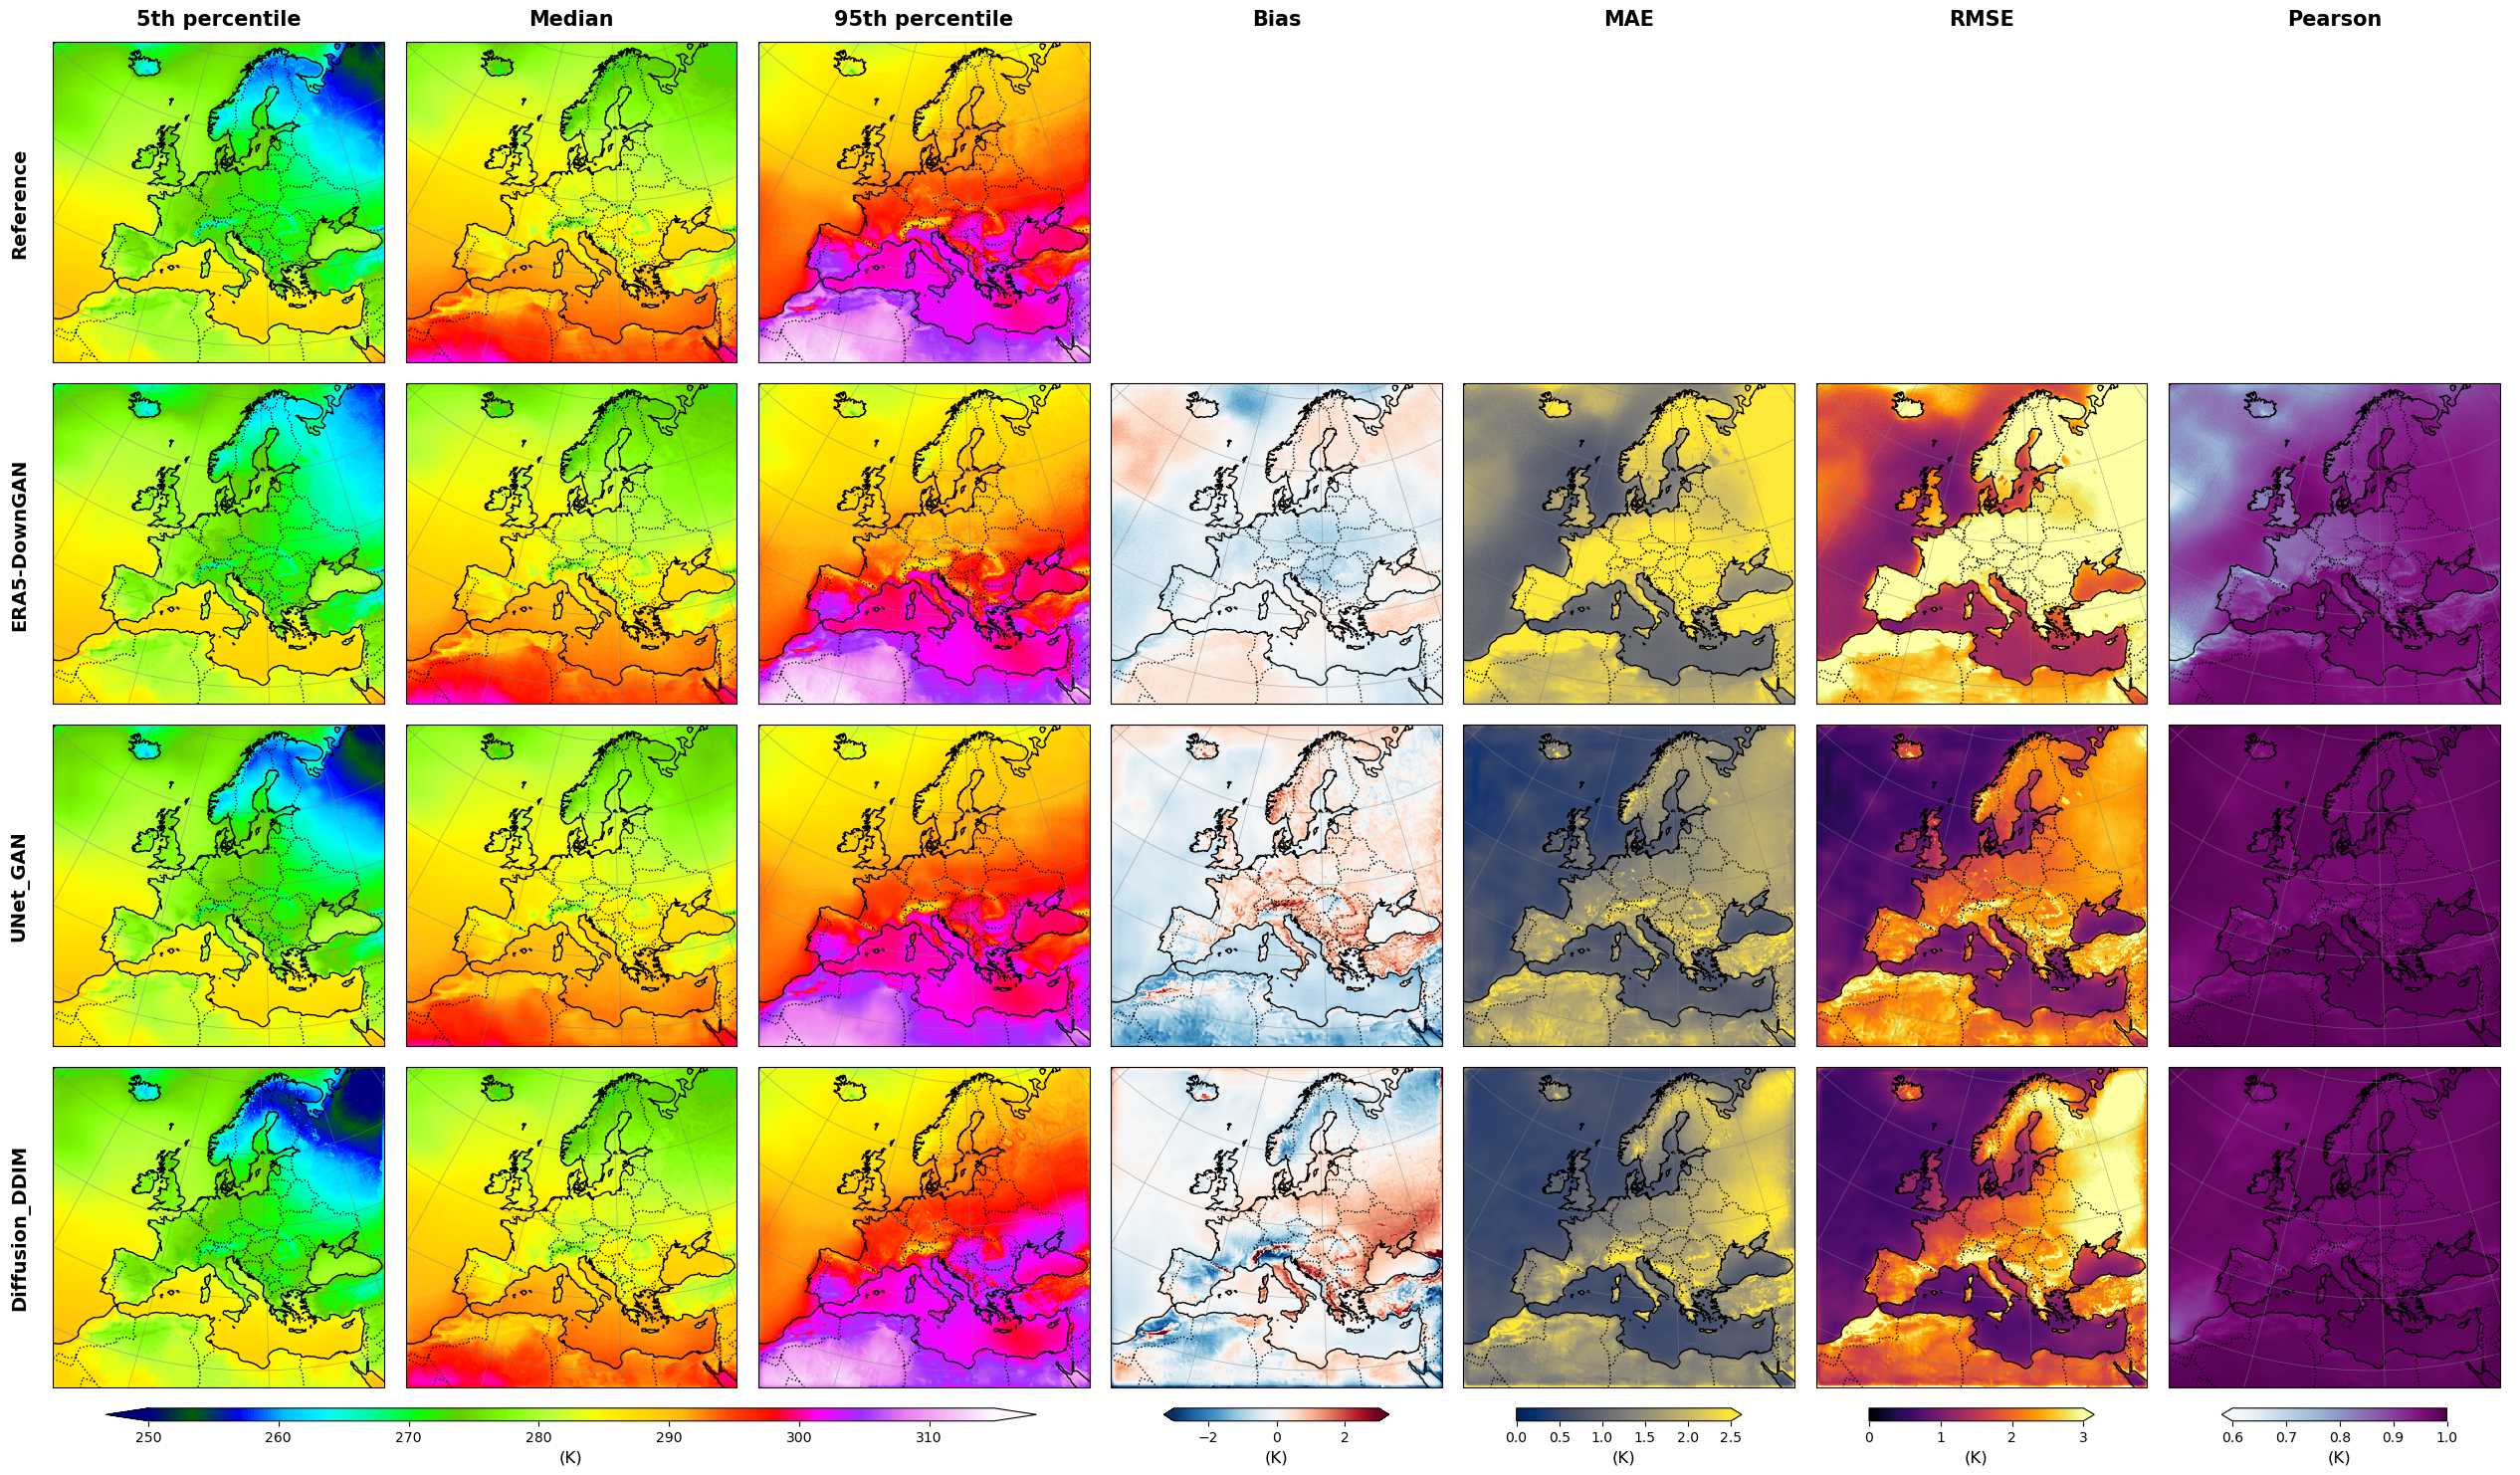

In [12]:
fig, axes, images = plot_metrics_panel(
    metrics,
    percentile_fields,
    plot_config
)

In [13]:
fig.savefig(
    OUTPUT_DIR / "metrics_panel.png",
    dpi=300,
    bbox_inches="tight"
)

## Metrics summary

In [14]:
from src.metrics import summarize_metric_distributions

df_summary = summarize_metric_distributions(metrics)

df_summary

,model,metric,min,max,p1,p5,p50,p95,p99
0,ERA5-DownGAN,bias,-1.767825,1.248289,-1.147208,-0.774211,-0.122684,0.560625,0.799790
1,ERA5-DownGAN,mae,0.674668,4.353074,0.776992,0.881273,1.923990,2.967762,3.370347
2,ERA5-DownGAN,rmse,0.864691,5.306297,0.988895,1.109658,2.491899,3.806541,4.412250
3,ERA5-DownGAN,correlation,0.523319,0.976188,0.732609,0.796059,0.928771,0.967775,0.971596
4,UNet_GAN,bias,-3.529155,3.773032,-1.752329,-1.229286,-0.182858,0.885131,1.571266
5,UNet_GAN,mae,0.259625,4.019284,0.338639,0.432715,1.356767,2.077893,2.408957
6,UNet_GAN,rmse,0.336998,4.678248,0.429921,0.575299,1.784055,2.606366,3.013340
7,UNet_GAN,correlation,0.869612,0.996328,0.944062,0.957225,0.975753,0.990247,0.992639
8,Diffusion_DDIM,bias,-5.452236,8.099176,-2.143475,-1.233050,-0.046589,1.215267,1.818737
9,Diffusion_DDIM,mae,0.399025,8.099176,0.445752,0.500522,1.272467,2.343214,2.763258


In [15]:
df_summary.to_csv(
    OUTPUT_DIR / "metric_distribution_summary.csv",
    index=False,
)

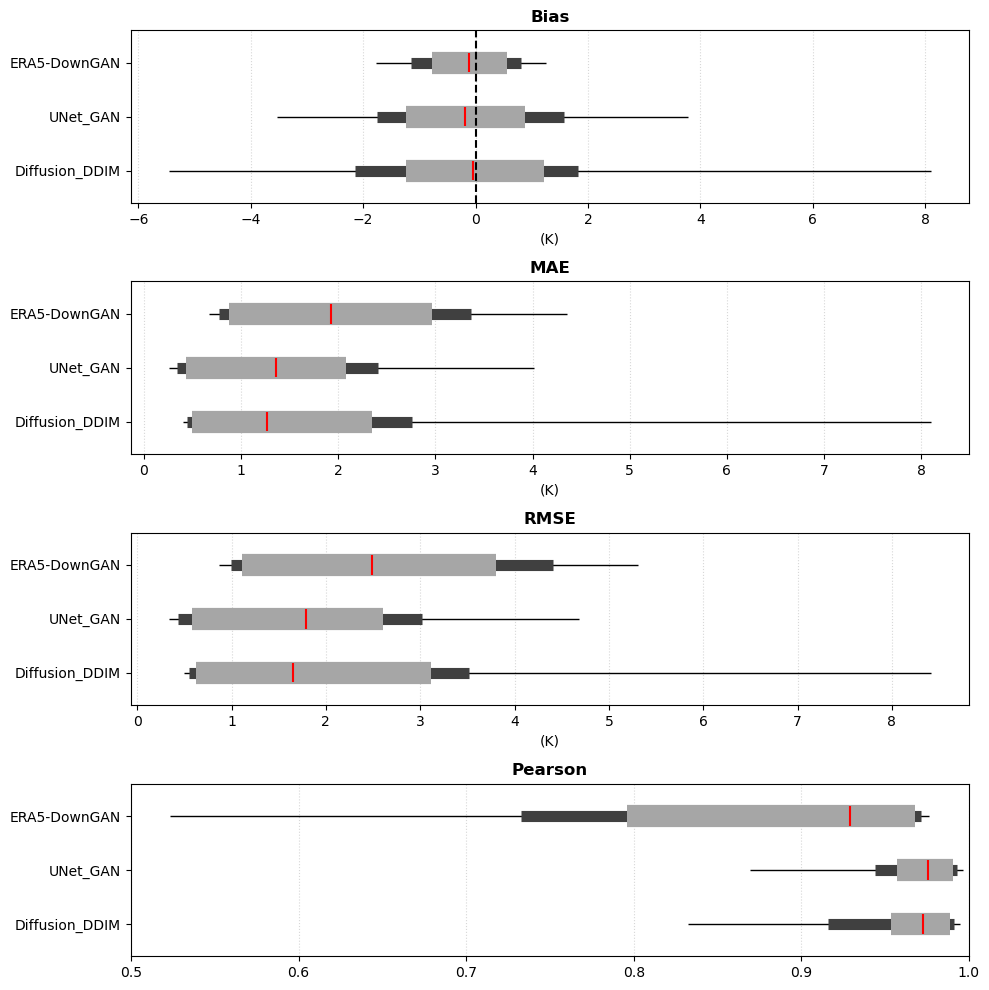

In [16]:
from src.plotting import plot_metric_summary

fig, ax = plot_metric_summary(df_summary)

In [17]:
fig.savefig(
    OUTPUT_DIR / "metrics_distribution.png",
    dpi=300,
    bbox_inches="tight"
)